In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import fsolve
from scipy.optimize import curve_fit
%matplotlib inline


In [2]:
#reads in file as 
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 

In [3]:
print(repsData.columns)

Index(['NAME', 'PARTY', 'DISTRICT', 'DAYS CLAIMED', 'TOTAL'], dtype='str')


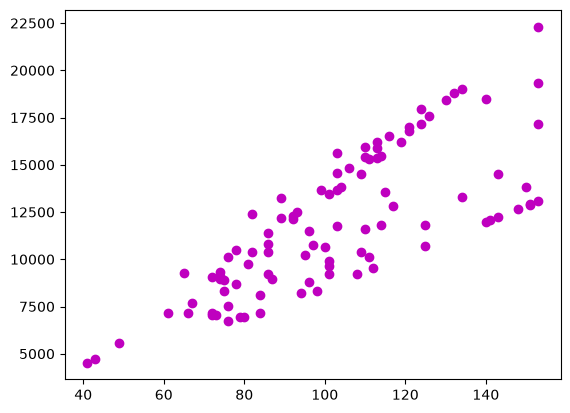

In [15]:
#reads in file using pandas, fixes some white space issue in the days claimed column i lost sleep over and spent WAYYYYYY too long on
#also probably a much better way exists but i kinda like that pandas uses the first row as a name for the columns and thats kinda convenient
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 
repsData.columns = repsData.columns.str.replace("\xa0", " ").str.strip()

#gets rid of the last row 
repsData = repsData.iloc[:-1]
#formats the total column to be just a float number 
repsData["TOTAL"] = repsData["TOTAL"].str.replace("$", "").str.replace(",", "").astype(float)

#turns the columns into variables numpy can use 
#**Todo** sort data by district before this 
districtReps = repsData["DISTRICT"].astype(int).to_numpy()
days = repsData["DAYS CLAIMED"].astype(int).to_numpy()
total = repsData["TOTAL"].astype(float).to_numpy()

plt.plot(days, total, 'mo')

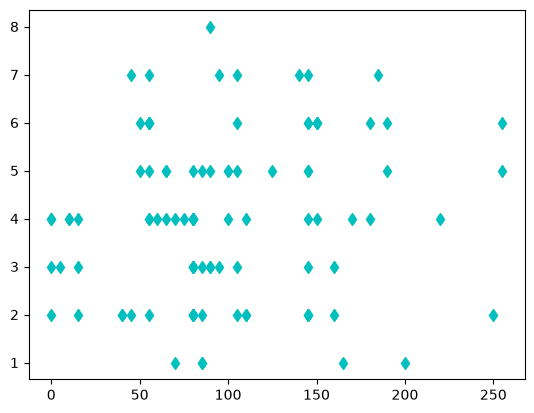

In [14]:
#reads in commitee file using pandas there were no issues this file is perfect 
commiteeData = pd.read_excel('Wisconsin_Assembly_2025_26_Committee_and_Hometown_Data.xlsx')

#turns columns into variables numpy can use
#**TODO** sort data by district 
districtCommitee = commiteeData["Assembly District"].astype(int).to_numpy()
miles = commiteeData["Approx. Distance to Madison (miles)"].astype(int).to_numpy()
commiteeCount =commiteeData["Committee Count"].astype(int).to_numpy()

plt.plot(miles, commiteeCount, 'cd')